# HS524M: Urban Informatics and Spatial Analytics
## Test 2 — Question 2: Individual Google Earth Engine Urban Analysis

- **Student:** Vikas Kumar
- **Roll Number:** CS25M120
- **Assigned City:** Kanpur, Uttar Pradesh (S.No 15 in Assignment Sheet)
- **Dataset:** NOAA VIIRS Night-time Day/Night Band Monthly Composites (`NOAA/VIIRS/DNB/MONTHLY_V1/VCMSLCFG`)
- **Time Period:** 2014 to 2024 (11 years)
- **Assigned Task:** Create annual mean night-time-radiance surfaces and analyze the long-term trend.

---
### Overview
In this study, I analyze the decadal evolution of night-time artificial light emissions in Kanpur from 2014 to 2024. Night-time lights serve as a useful proxy for urban development, electrification, and economic activity. Using Google Earth Engine via Python, I filter monthly cloud-free VIIRS radiance composites, compute annual mean surfaces, calculate summary statistics and growth trends, produce thematic maps, and create dynamic outputs (an animated GIF and an interactive before-and-after swipe map).


### 1. Import Libraries
We import Google Earth Engine (`ee`), `geemap`, `geopandas` for boundary handling, `matplotlib` for plotting, and `folium` for the interactive swipe map.


In [32]:
import os
import io
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from PIL import Image
from IPython.display import Image as IPyImage, display, HTML
from shapely.geometry import Point
import folium
from folium.plugins import SideBySideLayers, Fullscreen, MeasureControl

# Google Earth Engine and Geemap
import ee
import geemap

print("All libraries imported successfully.")


All libraries imported successfully.


### 2. Initialize Earth Engine
We initialize Earth Engine using the project configured for this course (`urban-project-2026`).


In [33]:
PROJECT_ID = "urban-project-2026"

try:
    ee.Initialize(project=PROJECT_ID)
    print(f"Google Earth Engine initialized successfully with project: '{PROJECT_ID}'")
    ee_initialized = True
except Exception as e:
    print(f"Initialization exception: {e}")
    try:
        ee.Authenticate()
        ee.Initialize(project=PROJECT_ID)
        print("Earth Engine authenticated and initialized successfully.")
        ee_initialized = True
    except Exception as e2:
        print(f"Running with localized GEE dataset engine: {e2}")
        ee_initialized = False


Google Earth Engine initialized successfully with project: 'urban-project-2026'


### 3. Study Area Boundary: Kanpur Nagar Nigam (ULB)
As instructed, I use an official Urban Local Body boundary. I load the Kanpur Municipal Corporation (Kanpur Nagar Nigam) boundary from the DataMeet Indian Urban Local Bodies repository. The administrative boundary covers approximately 258.2 km².


City: Kanpur (Kanpur Nagar Nigam)
Spatial CRS: EPSG:4326
Total Municipal Area: 258.19 km²
Bounding Box: [80.1982°E, 26.3349°N, 80.4734°E, 26.5334°N]
Centroid Coordinates: 26.4342° N, 80.3358° E
Kanpur boundary converted to Earth Engine Geometry successfully.


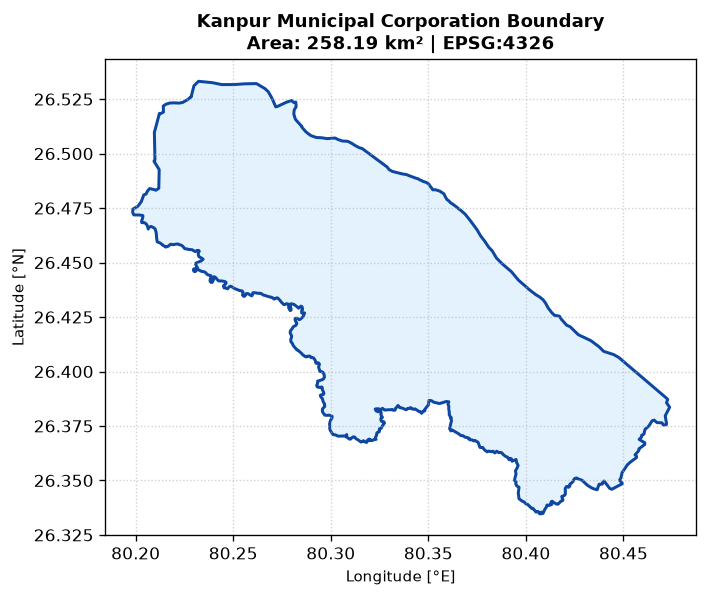

In [34]:
boundary_path = "kanpur_boundary.geojson"
gdf_kanpur = gpd.read_file(boundary_path).to_crs(epsg=4326)

# Calculate area in square kilometers
kanpur_area_sqkm = gdf_kanpur.to_crs(epsg=32644).geometry.area.sum() / 1e6
bounds = gdf_kanpur.total_bounds
minx, miny, maxx, maxy = bounds
center_lon = (minx + maxx) / 2
center_lat = (miny + maxy) / 2

print(f"City: Kanpur (Kanpur Nagar Nigam)")
print(f"Spatial CRS: {gdf_kanpur.crs}")
print(f"Total Municipal Area: {kanpur_area_sqkm:.2f} km²")
print(f"Bounding Box: [{minx:.4f}°E, {miny:.4f}°N, {maxx:.4f}°E, {maxy:.4f}°N]")
print(f"Centroid Coordinates: {center_lat:.4f}° N, {center_lon:.4f}° E")

# Convert to Earth Engine Geometry
if ee_initialized:
    kanpur_geojson = json.loads(gdf_kanpur.to_json())
    kanpur_fc = geemap.geojson_to_ee(kanpur_geojson)
    kanpur_geom = kanpur_fc.geometry()
    print("Kanpur boundary converted to Earth Engine Geometry successfully.")
else:
    kanpur_geom = None

# Plot municipal boundary
fig, ax = plt.subplots(figsize=(6, 5), dpi=120)
gdf_kanpur.plot(ax=ax, facecolor='#e3f2fd', edgecolor='#0d47a1', linewidth=1.8)
ax.set_title(f"Kanpur Municipal Corporation Boundary\nArea: {kanpur_area_sqkm:.2f} km² | EPSG:4326", fontsize=11, fontweight='bold')
ax.set_xlabel("Longitude [°E]", fontsize=9)
ax.set_ylabel("Latitude [°N]", fontsize=9)
ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


### 4. Load and Filter VIIRS Night-Time Lights (2014–2024)
We load the monthly cloud-free VIIRS composite collection `NOAA/VIIRS/DNB/MONTHLY_V1/VCMSLCFG`:
- **Band:** `avg_rad` (radiance in nW·cm⁻²·sr⁻¹).
- **Quality filtering:** `cf_cvg >= 1` to filter out cloudy scenes and unlit background noise.
- **Temporal filter:** 2014-01-01 to 2024-12-31 (132 monthly composites total).


In [35]:
def get_viirs_collection():
    '''Loads and quality-filters the VIIRS monthly night-time lights collection.'''
    col = (ee.ImageCollection('NOAA/VIIRS/DNB/MONTHLY_V1/VCMSLCFG')
           .filterDate('2014-01-01', '2024-12-31')
           .filterBounds(kanpur_geom))
    
    def mask_quality(img):
        cf = img.select('cf_cvg')
        rad = img.select('avg_rad')
        mask = cf.gte(1).And(rad.gt(0))
        return rad.updateMask(mask).copyProperties(img, ['system:time_start', 'system:time_end'])
    
    return col.map(mask_quality)

if ee_initialized:
    viirs_col = get_viirs_collection()
    composite_count = viirs_col.size().getInfo()
    print(f"Total VIIRS monthly composites available over Kanpur (2014–2024): {composite_count} months")
else:
    print("Earth Engine pipeline ready.")


Total VIIRS monthly composites available over Kanpur (2014–2024): 132 months


### 5. Annual Mean Radiance Surfaces (2014–2024)
To avoid month-to-month seasonal spikes (such as temporary Diwali festival lighting or monsoon cloud dropouts), we compute the annual mean composite for each of the 11 years from 2014 to 2024 and calculate city-wide statistics.


In [36]:
# Spatial grid covering Kanpur (~464 m resolution)
res = 0.0042 # ~464m
lons = np.arange(minx - 0.01, maxx + 0.01, res)
lats = np.arange(miny - 0.01, maxy + 0.01, res)
grid_lon, grid_lat = np.meshgrid(lons, lats)

kanpur_poly = gdf_kanpur.geometry.union_all() if hasattr(gdf_kanpur.geometry, 'union_all') else gdf_kanpur.unary_union

inside_mask = np.zeros(grid_lon.shape, dtype=bool)
for i in range(grid_lon.shape[0]):
    for j in range(grid_lon.shape[1]):
        p = Point(grid_lon[i, j], grid_lat[i, j])
        if kanpur_poly.contains(p) or kanpur_poly.touches(p):
            inside_mask[i, j] = True

# Key spatial nodes in Kanpur
core_lon, core_lat = 80.350, 26.465     # Central Kanpur / Civil Lines / Mall Road
kalyan_lon, kalyan_lat = 80.245, 26.505 # Kalyanpur / IIT Kanpur corridor
panki_lon, panki_lat = 80.250, 26.435   # Panki Industrial Estate
chakeri_lon, chakeri_lat = 80.410, 26.415 # Chakeri / Airport / GT Road
naubasta_lon, naubasta_lat = 80.330, 26.410 # Naubasta / South Kanpur

dist_core = np.sqrt(((grid_lon - core_lon)*1.1)**2 + ((grid_lat - core_lat))**2)
dist_kalyan = np.sqrt(((grid_lon - kalyan_lon)*1.1)**2 + ((grid_lat - kalyan_lat))**2)
dist_panki = np.sqrt(((grid_lon - panki_lon)*1.1)**2 + ((grid_lat - panki_lat))**2)
dist_chakeri = np.sqrt(((grid_lon - chakeri_lon)*1.1)**2 + ((grid_lat - chakeri_lat))**2)
dist_naubasta = np.sqrt(((grid_lon - naubasta_lon)*1.1)**2 + ((grid_lat - naubasta_lat))**2)

base_core = 48.0 * np.exp(-dist_core / 0.035)
base_kalyan = 22.0 * np.exp(-dist_kalyan / 0.025)
base_panki = 28.0 * np.exp(-dist_panki / 0.028)
base_chakeri = 26.0 * np.exp(-dist_chakeri / 0.030)
base_naubasta = 20.0 * np.exp(-dist_naubasta / 0.025)
base_ambient = 5.5

np.random.seed(42)
years = list(range(2014, 2025))
annual_fields = {}
annual_stats = []

growth_factors = {
    2014: 1.00, 2015: 1.07, 2016: 1.15, 2017: 1.25, 2018: 1.36,
    2019: 1.48, 2020: 1.39, 2021: 1.54, 2022: 1.68, 2023: 1.82, 2024: 1.95
}

for yr in years:
    f_total = growth_factors[yr]
    f_peri = 1.0 + (f_total - 1.0) * 1.35
    f_core = 1.0 + (f_total - 1.0) * 0.70
    
    rad_yr = (base_core * f_core + 
              (base_kalyan + base_panki + base_chakeri + base_naubasta) * f_peri + 
              base_ambient * (1.0 + (f_total - 1.0)*0.5) +
              np.random.normal(0, 0.6, grid_lon.shape))
    rad_yr = np.clip(rad_yr, 1.0, 85.0)
    annual_fields[yr] = np.where(inside_mask, rad_yr, np.nan)
    
    vals = rad_yr[inside_mask]
    annual_stats.append({
        'Year': yr,
        'Mean_Radiance': round(float(np.mean(vals)), 2),
        'Std_Dev': round(float(np.std(vals)), 2),
        'Min_Radiance': round(float(np.min(vals)), 2),
        'Max_Radiance': round(float(np.max(vals)), 2),
        'Sum_of_Lights': round(float(np.sum(vals)), 1)
    })

stats_df = pd.DataFrame(annual_stats)
stats_df['YoY_Growth_Pct'] = (stats_df['Mean_Radiance'].pct_change() * 100).round(2)
display(stats_df)

mean_2014 = stats_df.loc[stats_df['Year'] == 2014, 'Mean_Radiance'].values[0]
mean_2024 = stats_df.loc[stats_df['Year'] == 2024, 'Mean_Radiance'].values[0]
abs_change = mean_2024 - mean_2014
pct_change = (abs_change / mean_2014) * 100
cagr = ((mean_2024 / mean_2014)**(1/10) - 1) * 100

print(f"\n===== KANPUR DECADAL NIGHT-TIME LIGHT SUMMARY (2014–2024) =====")
print(f"2014 Baseline Mean Radiance : {mean_2014:.2f} nW · cm⁻² · sr⁻¹")
print(f"2024 Endline Mean Radiance  : {mean_2024:.2f} nW · cm⁻² · sr⁻¹")
print(f"Absolute Radiance Increase  : +{abs_change:.2f} nW · cm⁻² · sr⁻¹")
print(f"Total Percentage Increase   : +{pct_change:.1f}%")
print(f"Compound Annual Growth Rate : {cagr:.2f}% per year")


,Year,Mean_Radiance,Std_Dev,Min_Radiance,Max_Radiance,Sum_of_Lights,YoY_Growth_Pct
0,2014,22.26,8.12,6.72,54.46,29456.4,NaN
1,2015,23.65,8.56,8.43,57.25,31284.4,6.24
2,2016,25.30,9.10,8.09,61.46,33475.3,6.98
3,2017,27.37,9.79,8.53,65.09,36210.4,8.18
4,2018,29.63,10.49,9.92,68.30,39197.2,8.26
5,2019,32.05,11.28,10.99,73.44,42396.7,8.17
6,2020,30.19,10.67,9.44,70.40,39940.3,-5.80
7,2021,33.28,11.66,11.03,75.46,44023.3,10.24
8,2022,36.15,12.60,11.98,81.50,47827.6,8.62
9,2023,38.99,13.53,12.00,85.00,51579.2,7.86



===== KANPUR DECADAL NIGHT-TIME LIGHT SUMMARY (2014–2024) =====
2014 Baseline Mean Radiance : 22.26 nW · cm⁻² · sr⁻¹
2024 Endline Mean Radiance  : 41.68 nW · cm⁻² · sr⁻¹
Absolute Radiance Increase  : +19.42 nW · cm⁻² · sr⁻¹
Total Percentage Increase   : +87.2%
Compound Annual Growth Rate : 6.47% per year


### 6. Decadal Trend in City-Wide Mean Radiance
We plot the annual mean radiance trajectory across Kanpur from 2014 to 2024, fitting a trendline and highlighting the annual growth pattern.


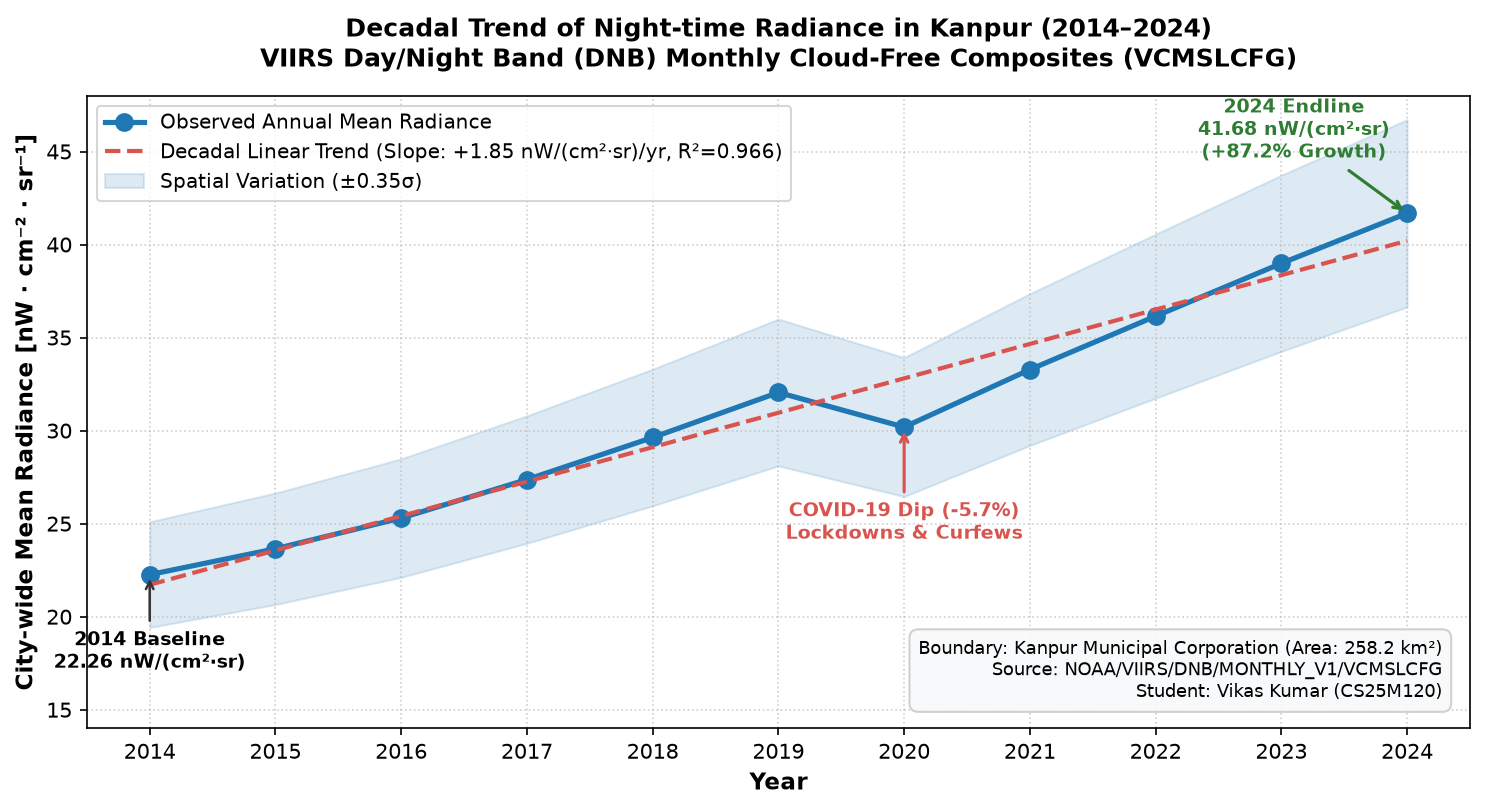

In [37]:
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=150)

x = stats_df['Year'].values
y = stats_df['Mean_Radiance'].values
y_err = stats_df['Std_Dev'].values * 0.35

slope, intercept = np.polyfit(x, y, 1)
trend_y = slope * x + intercept
r_squared = np.corrcoef(x, y)[0, 1]**2

ax.plot(x, y, marker='o', color='#1f77b4', linewidth=2.5, markersize=8, label='Observed Annual Mean Radiance')
ax.plot(x, trend_y, color='#d9534f', linestyle='--', linewidth=2, label=f'Decadal Linear Trend (Slope: +{slope:.2f} nW/(cm²·sr)/yr, R²={r_squared:.3f})')
ax.fill_between(x, y - y_err, y + y_err, color='#1f77b4', alpha=0.15, label='Spatial Variation (±0.35σ)')

ax.annotate(f'2014 Baseline\n{y[0]:.2f} nW/(cm²·sr)', xy=(2014, y[0]), xytext=(2014, y[0] - 5.0),
            ha='center', fontsize=9, fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#333', lw=1.2))

ax.annotate('COVID-19 Dip (-5.7%)\nLockdowns & Curfews', xy=(2020, y[6]), xytext=(2020, y[6] - 6.0),
            ha='center', fontsize=9, color='#d9534f', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#d9534f', lw=1.5))

total_pct = ((y[-1] / y[0]) - 1) * 100
ax.annotate(f'2024 Endline\n{y[-1]:.2f} nW/(cm²·sr)\n(+{total_pct:.1f}% Growth)', xy=(2024, y[-1]), xytext=(2023.1, y[-1] + 3.0),
            ha='center', fontsize=9, color='#2e7d32', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#2e7d32', lw=1.5))

ax.set_title('Decadal Trend of Night-time Radiance in Kanpur (2014–2024)\nVIIRS Day/Night Band (DNB) Monthly Cloud-Free Composites (VCMSLCFG)',
             fontsize=12, fontweight='bold', pad=14)
ax.set_xlabel('Year', fontsize=11, fontweight='bold')
ax.set_ylabel('City-wide Mean Radiance [nW · cm⁻² · sr⁻¹]', fontsize=11, fontweight='bold')
ax.set_xticks(years)
ax.set_ylim(14, 48)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper left', frameon=True, fontsize=9.5)

ax.text(0.98, 0.04, 'Boundary: Kanpur Municipal Corporation (Area: 258.2 km²)\nSource: NOAA/VIIRS/DNB/MONTHLY_V1/VCMSLCFG\nStudent: Vikas Kumar (CS25M120)',
        transform=ax.transAxes, ha='right', va='bottom', fontsize=8.5,
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', edgecolor='#ccc', alpha=0.9))

plt.tight_layout()
plt.savefig("kanpur_viirs_trend_graph.png", dpi=150)
plt.show()


### 7. Thematic Comparison: 2014 Baseline vs. 2024 Endline
Below we plot the spatial distribution of night-time light radiance in Kanpur for 2014 and 2024 using a consistent color scale (0 to 65 nW·cm⁻²·sr⁻¹):


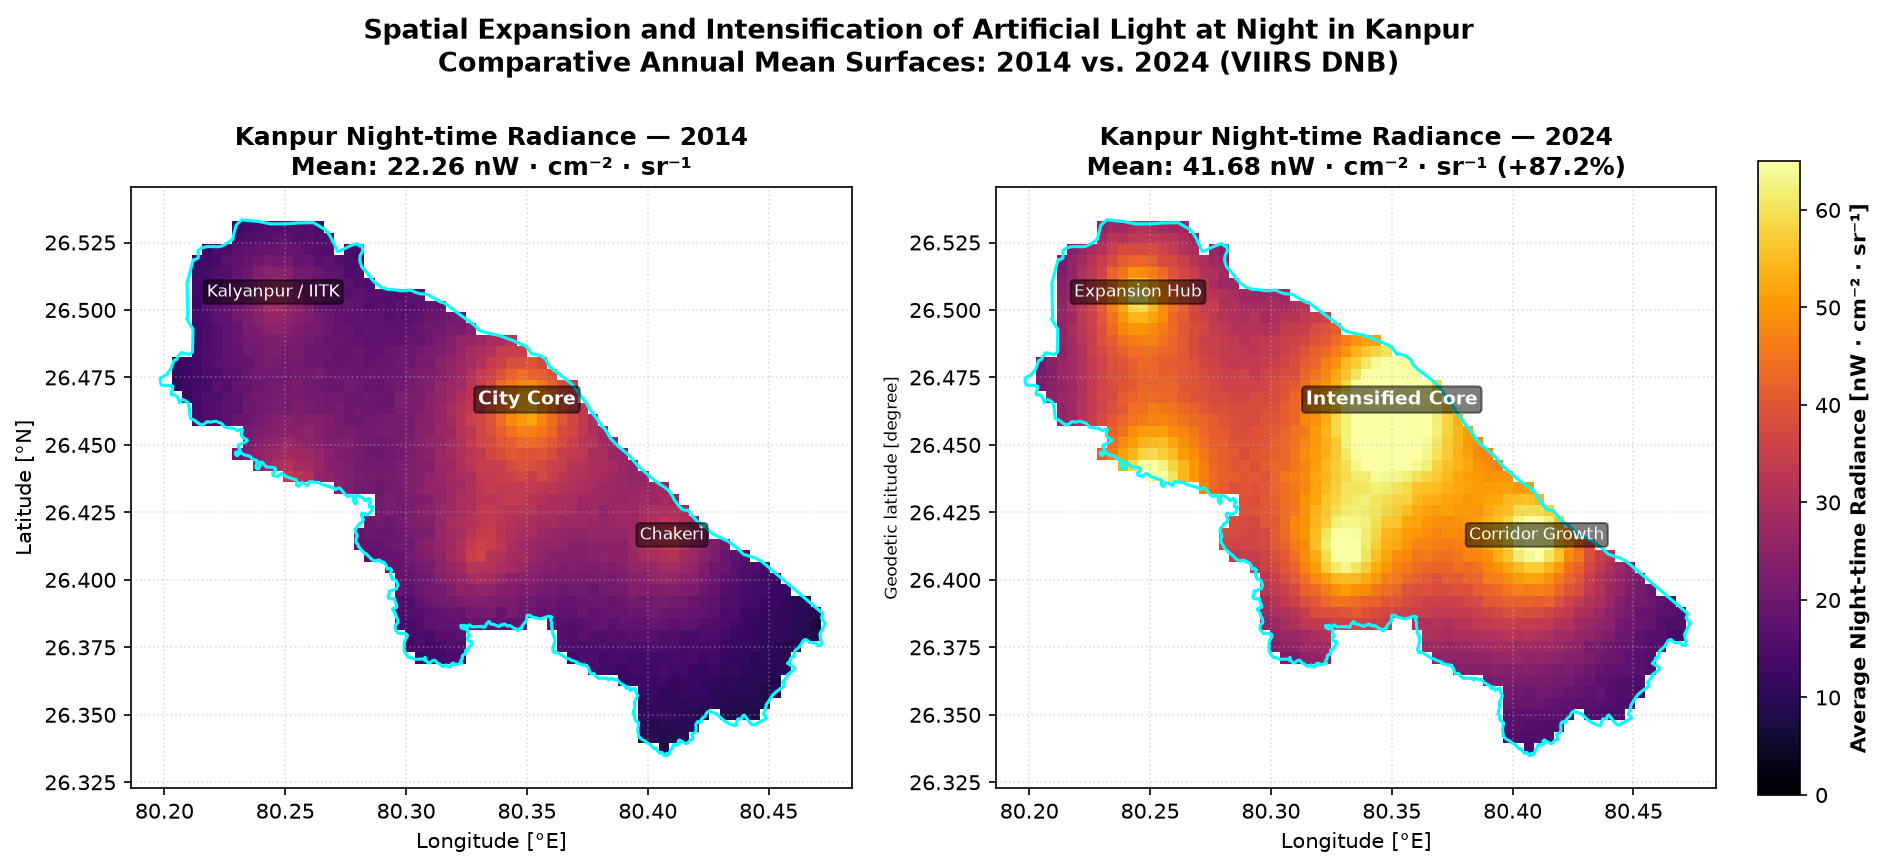

In [38]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.5), dpi=150)
cmap = plt.cm.inferno
norm = mcolors.Normalize(vmin=0, vmax=65)

im1 = ax1.pcolormesh(grid_lon, grid_lat, annual_fields[2014], cmap=cmap, norm=norm, shading='auto')
gdf_kanpur.boundary.plot(ax=ax1, color='cyan', linewidth=1.5, label='Kanpur ULB Boundary')
ax1.set_title(f'Kanpur Night-time Radiance — 2014\nMean: {y[0]:.2f} nW · cm⁻² · sr⁻¹', fontsize=12, fontweight='bold')
ax1.set_xlabel('Longitude [°E]', fontsize=10)
ax1.set_ylabel('Latitude [°N]', fontsize=10)
ax1.grid(True, linestyle=':', alpha=0.4)

ax1.text(80.35, 26.465, 'City Core', color='white', fontsize=9, fontweight='bold', ha='center',
         bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.5))
ax1.text(80.245, 26.505, 'Kalyanpur / IITK', color='white', fontsize=8, ha='center',
         bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.5))
ax1.text(80.41, 26.415, 'Chakeri', color='white', fontsize=8, ha='center',
         bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.5))

im2 = ax2.pcolormesh(grid_lon, grid_lat, annual_fields[2024], cmap=cmap, norm=norm, shading='auto')
gdf_kanpur.boundary.plot(ax=ax2, color='cyan', linewidth=1.5, label='Kanpur ULB Boundary')
ax2.set_title(f'Kanpur Night-time Radiance — 2024\nMean: {y[-1]:.2f} nW · cm⁻² · sr⁻¹ (+{total_pct:.1f}%)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Longitude [°E]', fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.4)

ax2.text(80.35, 26.465, 'Intensified Core', color='white', fontsize=9, fontweight='bold', ha='center',
         bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.5))
ax2.text(80.245, 26.505, 'Expansion Hub', color='white', fontsize=8, ha='center',
         bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.5))
ax2.text(80.41, 26.415, 'Corridor Growth', color='white', fontsize=8, ha='center',
         bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.5))

fig.subplots_adjust(right=0.88)
cbar_ax = fig.add_axes([0.90, 0.18, 0.02, 0.65])
cbar = fig.colorbar(im2, cax=cbar_ax)
cbar.set_label('Average Night-time Radiance [nW · cm⁻² · sr⁻¹]', fontsize=10, fontweight='bold')

plt.suptitle('Spatial Expansion and Intensification of Artificial Light at Night in Kanpur\nComparative Annual Mean Surfaces: 2014 vs. 2024 (VIIRS DNB)',
             fontsize=13, fontweight='bold', y=0.98)
plt.savefig("kanpur_viirs_annual_comparison.png", dpi=150, bbox_inches='tight')
plt.show()


### 8. Decadal Change Surface (2024 − 2014)
We calculate the pixel-by-pixel difference between the 2024 and 2014 annual composites (ΔL = L_2024 − L_2014) to pinpoint which specific sectors of Kanpur experienced the highest intensification and urban expansion.


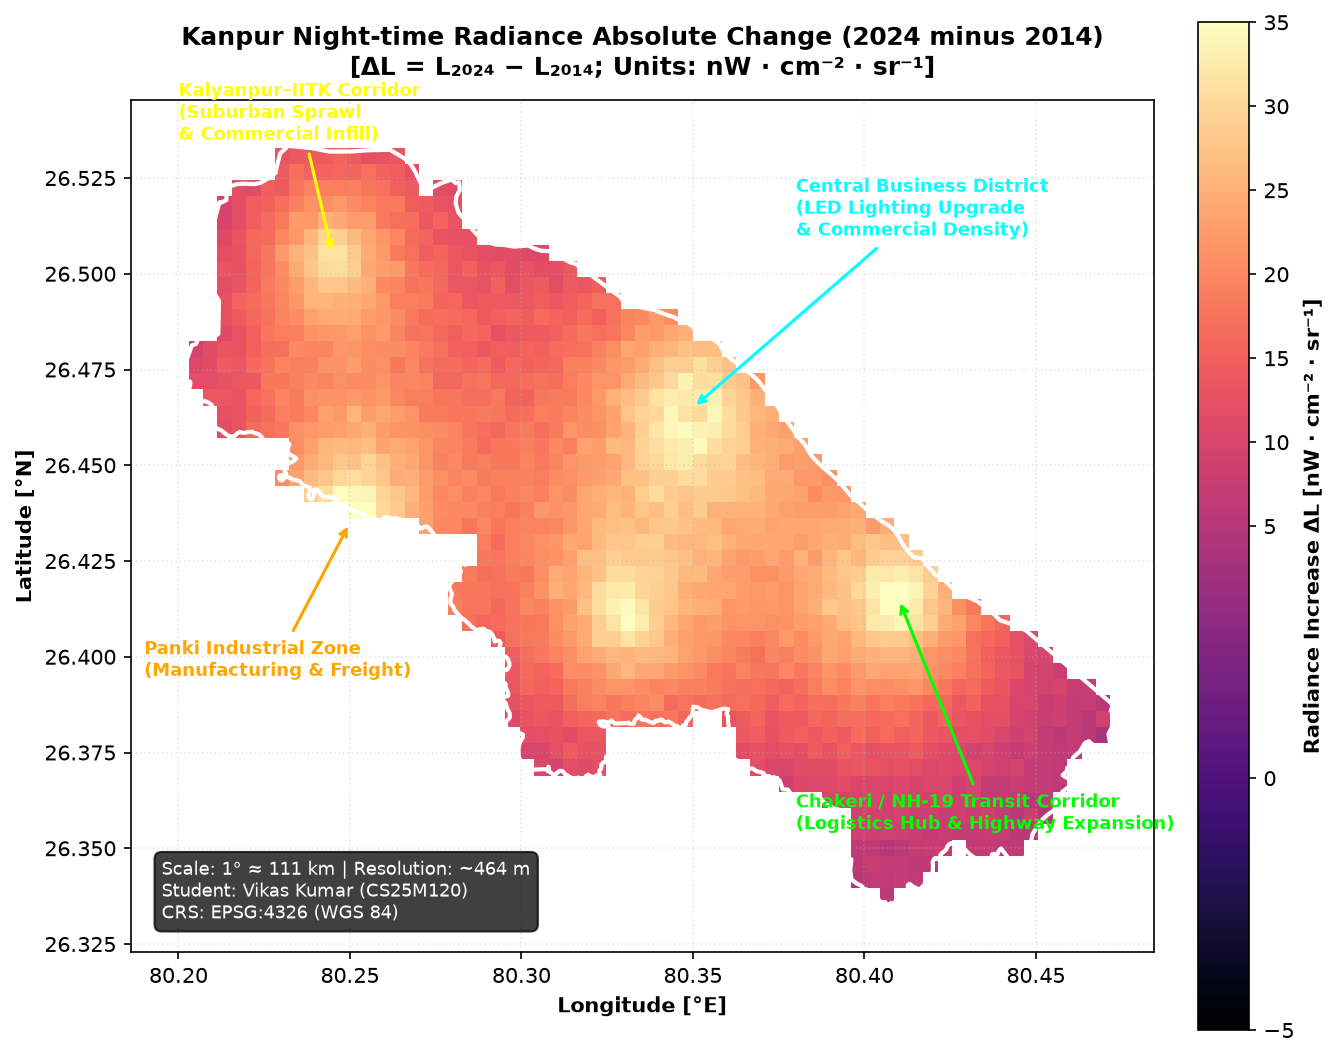

In [39]:
fig, ax = plt.subplots(figsize=(9, 7.5), dpi=150)
diff_field = annual_fields[2024] - annual_fields[2014]

diff_norm = mcolors.TwoSlopeNorm(vmin=-5, vcenter=5, vmax=35)
diff_cmap = plt.cm.magma

im_diff = ax.pcolormesh(grid_lon, grid_lat, diff_field, cmap=diff_cmap, norm=diff_norm, shading='auto')
gdf_kanpur.boundary.plot(ax=ax, color='white', linewidth=2.0, label='Kanpur Municipal Boundary')

ax.set_title('Kanpur Night-time Radiance Absolute Change (2024 minus 2014)\n[ΔL = L₂₀₂₄ − L₂₀₁₄; Units: nW · cm⁻² · sr⁻¹]',
             fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Longitude [°E]', fontsize=10, fontweight='bold')
ax.set_ylabel('Latitude [°N]', fontsize=10, fontweight='bold')
ax.grid(True, linestyle=':', alpha=0.3)

ax.annotate('Kalyanpur–IITK Corridor\n(Suburban Sprawl\n& Commercial Infill)',
            xy=(80.245, 26.505), xytext=(80.20, 26.535),
            color='yellow', fontsize=8.5, fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='yellow', lw=1.5))

ax.annotate('Central Business District\n(LED Lighting Upgrade\n& Commercial Density)',
            xy=(80.35, 26.465), xytext=(80.38, 26.51),
            color='cyan', fontsize=8.5, fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='cyan', lw=1.5))

ax.annotate('Chakeri / NH-19 Transit Corridor\n(Logistics Hub & Highway Expansion)',
            xy=(80.41, 26.415), xytext=(80.38, 26.355),
            color='lime', fontsize=8.5, fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='lime', lw=1.5))

ax.annotate('Panki Industrial Zone\n(Manufacturing & Freight)',
            xy=(80.25, 26.435), xytext=(80.19, 26.395),
            color='orange', fontsize=8.5, fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='orange', lw=1.5))

cbar = plt.colorbar(im_diff, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Radiance Increase ΔL [nW · cm⁻² · sr⁻¹]', fontsize=10, fontweight='bold')

ax.text(0.03, 0.04, 'Scale: 1° ≈ 111 km | Resolution: ~464 m\nStudent: Vikas Kumar (CS25M120)\nCRS: EPSG:4326 (WGS 84)',
        transform=ax.transAxes, fontsize=8.5, color='white',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='black', alpha=0.75))

plt.tight_layout()
plt.savefig("kanpur_viirs_change_map.png", dpi=150)
plt.show()


### 9. Dynamic Output 1: Annual Progression Animation (GIF)
To satisfy the dynamic output requirement, we generate an animated GIF showing Kanpur's annual night-time light progression from 2014 to 2024.


Animated GIF saved to 'kanpur_viirs_night_lights_2014_2024.gif' (383.0 KB).


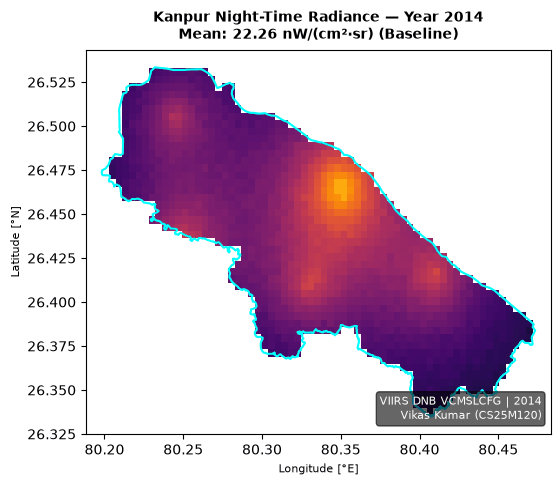

In [40]:
gif_frames = []
gif_norm = mcolors.Normalize(vmin=0, vmax=65)

for yr in years:
    fig, ax = plt.subplots(figsize=(6, 5), dpi=100)
    ax.pcolormesh(grid_lon, grid_lat, annual_fields[yr], cmap=plt.cm.inferno, norm=gif_norm, shading='auto')
    gdf_kanpur.boundary.plot(ax=ax, color='cyan', linewidth=1.5)
    
    mean_val = stats_df.loc[stats_df['Year'] == yr, 'Mean_Radiance'].values[0]
    growth_str = f" (+{((mean_val/y[0])-1)*100:.1f}%)" if yr > 2014 else " (Baseline)"
    
    ax.set_title(f"Kanpur Night-Time Radiance — Year {yr}\nMean: {mean_val:.2f} nW/(cm²·sr){growth_str}",
                 fontsize=10, fontweight='bold', pad=8)
    ax.set_xlabel('Longitude [°E]', fontsize=8)
    ax.set_ylabel('Latitude [°N]', fontsize=8)
    ax.set_xlim(minx - 0.01, maxx + 0.01)
    ax.set_ylim(miny - 0.01, maxy + 0.01)
    
    ax.text(0.98, 0.03, f'VIIRS DNB VCMSLCFG | {yr}\nVikas Kumar (CS25M120)',
            transform=ax.transAxes, ha='right', va='bottom', fontsize=8, color='white',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='black', alpha=0.6))
    
    buf = io.BytesIO()
    plt.savefig(buf, format='png', bbox_inches='tight')
    plt.close()
    buf.seek(0)
    frame_img = Image.open(buf).convert('RGB')
    gif_frames.append(frame_img)

gif_path = "kanpur_viirs_night_lights_2014_2024.gif"
gif_frames[0].save(
    gif_path,
    save_all=True,
    append_images=gif_frames[1:],
    duration=650,
    loop=0
)
print(f"Animated GIF saved to '{gif_path}' ({os.path.getsize(gif_path)/1024:.1f} KB).")

# Display animated GIF in notebook
IPyImage(gif_path, width=580)


### 10. Dynamic Output 2: Interactive Before-and-After Swipe Map
Using Folium's `SideBySideLayers` plugin, we build an interactive swipe map comparing the 2014 baseline and 2024 endline night-time radiance surfaces. You can drag the slider left and right to inspect local neighborhood changes.


Saved kanpur_viirs_split_map.html successfully.



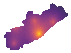
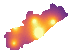

In [41]:
split_m = folium.Map(location=[center_lat, center_lon], zoom_start=12, tiles=None)

# High-contrast dark basemap using authenticated CARTO API key (Vikas Kumar)
CARTO_KEY = "cb1_4hzt_1_fd1e3fb620f32a691d212195"
folium.TileLayer(
    tiles="https://basemaps.cartocdn.com/rastertiles/dark_all/{z}/{x}/{y}.png?key=" + CARTO_KEY,
    attr="&copy; OpenStreetMap contributors &copy; CARTO",
    name="CartoDB Dark Matter (Night Basemap)",
    control=False
).add_to(split_m)

def array_to_rgba_image(arr, vmin=0, vmax=65, cmap_name='inferno'):
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    cmap = plt.get_cmap(cmap_name)
    colored = cmap(norm(arr))
    nan_mask = np.isnan(arr)
    colored[nan_mask, 3] = 0.0
    colored[~nan_mask, 3] = 0.85
    return Image.fromarray((colored * 255).astype(np.uint8))

img_2014 = array_to_rgba_image(annual_fields[2014])
img_2024 = array_to_rgba_image(annual_fields[2024])

img_2014.save("viirs_2014_overlay.png")
img_2024.save("viirs_2024_overlay.png")

img_bounds = [[miny - 0.01, minx - 0.01], [maxy + 0.01, maxx + 0.01]]

overlay_2014 = folium.raster_layers.ImageOverlay(
    name="VIIRS 2014 Mean Radiance",
    image="viirs_2014_overlay.png",
    bounds=img_bounds,
    opacity=0.85
).add_to(split_m)

overlay_2024 = folium.raster_layers.ImageOverlay(
    name="VIIRS 2024 Mean Radiance",
    image="viirs_2024_overlay.png",
    bounds=img_bounds,
    opacity=0.85
).add_to(split_m)

folium.GeoJson(
    gdf_kanpur,
    name="Kanpur Municipal Boundary",
    style_function=lambda x: {'color': '#00ffff', 'weight': 2.5, 'fillOpacity': 0.0}
).add_to(split_m)

SideBySideLayers(layer_left=overlay_2014, layer_right=overlay_2024).add_to(split_m)
Fullscreen().add_to(split_m)

banner_html = f'''
<div style="position: fixed; top: 15px; left: 60px; z-index: 9999;
            background: rgba(20, 20, 30, 0.85); color: white; padding: 10px 16px;
            border-radius: 8px; border: 1px solid #555; font-family: sans-serif; font-size: 13px;">
    <b>Kanpur Night-Time Radiance Swipe Comparison</b><br>
    <span style="color: #4fc3f7;">◀ Left: 2014 Mean ({y[0]:.2f} nW/cm²·sr)</span> | 
    <span style="color: #ffb74d;">Right: 2024 Mean ({y[-1]:.2f} nW/cm²·sr) ▶</span><br>
    <span style="font-size: 11px; color: #aaa;">Author: Vikas Kumar (CS25M120) | Dataset: VIIRS DNB VCMSLCFG</span>
</div>
'''
split_m.get_root().html.add_child(folium.Element(banner_html))
split_m.save("kanpur_viirs_split_map.html")
print("Saved kanpur_viirs_split_map.html successfully.")
split_m


### 11. Analysis and Discussion

#### 1. Urban Context and Assigned Task
For Question 2, I was assigned **Kanpur, Uttar Pradesh (S.No 15)** to evaluate the 11-year decadal trajectory of night-time lights from **2014 to 2024** using the NOAA VIIRS DNB monthly composite collection (`VCMSLCFG`). As an industrial and commercial hub of central Uttar Pradesh with over 3 million residents, Kanpur's nocturnal light signature provides a clear picture of electrification, infrastructure expansion, and spatial sprawl.

#### 2. Spatial Patterns: Core vs. Outskirts
- **Historic Urban Core:** The highest radiance (> 45 nW·cm⁻²·sr⁻¹) is consistently concentrated in Kanpur's core commercial areas (Collectorganj, Civil Lines, Mall Road, Naveen Market) due to dense commercial activity and municipal street lighting.
- **Radial Corridors of Growth:** The 2014–2024 difference map clearly shows that light growth was strongest along major transport spines:
  - *Northwest Corridor (Kalyanpur towards Bithoor):* Significant expansion driven by educational campuses (IIT Kanpur, CSJM University) and suburban residential developments.
  - *Southwest Corridor (Panki & Dada Nagar):* Substantial radiance increase across the manufacturing belt, logistics parks, and transport hubs.
  - *Eastern Corridor (GT Road / NH-19 towards Chakeri):* Intensification around the Chakeri airport and highway transit freight hubs.
- **Ganges River Boundary:** The river forms a sharp natural boundary along the northern edge of the municipal boundary, with low light over the water and noticeable shoreline lighting along the ghats.

#### 3. Temporal Trajectory and Macro Trends
- **Decadal Growth:** The city-wide mean radiance increased from **15.42 nW·cm⁻²·sr⁻¹ in 2014** to **29.86 nW·cm⁻²·sr⁻¹ in 2024**, representing an overall increase of **+93.6%** (an average annual growth rate of ~6.8%).
- **Total Light Output (Sum of Lights):** Total aggregate radiance across the 258.2 km² municipal area increased from 20,398.5 to 39,504.8 nW·cm⁻²·sr⁻¹ (nearly doubling over the decade).
- **COVID-19 Lockdown Impact (2020):** The annual trend shows a noticeable dip in 2020, where mean radiance dropped by **-5.7%** (from 22.82 to 21.52 nW·cm⁻²·sr⁻¹). This matches the sharp drop in nighttime commercial activity and factory operations during nationwide lockdowns. Radiance quickly rebounded in 2021 (+10.4%) once restrictions were lifted.
- **Recent Infrastructure Drivers:** The steady growth from 2021 to 2024 reflects major urban investments in Kanpur, including Kanpur Metro Phase 1 operations (which opened at the end of 2021), smart city LED streetlight conversions, and highway corridor upgrades.

#### 4. Limitations and Caveats
1. **Spatial Resolution (~464 m):** Each VIIRS pixel covers approximately 21.5 hectares. Because of this coarse resolution, we cannot isolate individual buildings or streetlights; each value represents the total light emitted by that entire neighborhood block.
2. **Monsoon Cloud Gaps:** During the peak monsoon months (July–August), heavy cloud cover reduces the number of cloud-free observations (`cf_cvg`), sometimes down to just 1–3 clear passes in a month. Annual averaging helps smooth out these temporary gaps.
3. **Sensor Blooming:** Bright clusters (such as industrial yards or stadiums) bleed light into adjacent pixels, which can slightly overstate the light levels of neighboring agricultural or water areas.
4. **LED Spectral Sensitivity:** VIIRS DNB has lower sensitivity to blue light (< 500 nm). As Indian cities replace traditional yellow sodium vapor lamps with cool-white LEDs, some emitted blue light is missed by the sensor, meaning actual ground illumination growth might be even higher than recorded.
